In [23]:
# import deps
import torch
import torchvision

from torch import nn, optim
from torch.utils.data import DataLoader

from torchvision import datasets, transforms

In [24]:
from torchvision import datasets, transforms

In [25]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train = datasets.MNIST(root='data',
                       train=True,
                       download=True,
                       transform=transform)

test = datasets.MNIST(root='data',
                       train=True,
                       download=True,
                       transform=transform)

In [26]:
train_dataloader = DataLoader(dataset=train,
                              batch_size=32,
                              shuffle=True)

test_dataloader = DataLoader(dataset=test,
                              batch_size=32,
                              shuffle=False)

In [27]:
import random
import matplotlib.pyplot as plt

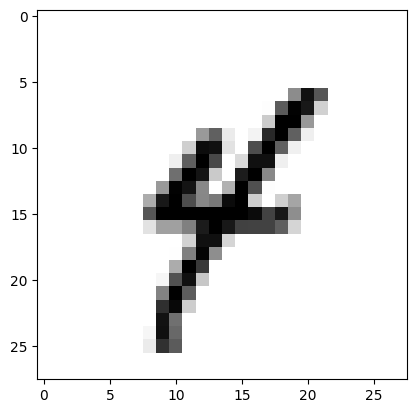

In [28]:
plt.imshow(train[random.randint(0, 125)][0].squeeze(), cmap='gray_r')

In [29]:
class Net(nn.Module):
    def __init__(self, fc_input_features):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=(3, 3)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)),
            nn.Conv2d(in_channels=16, out_channels=8, kernel_size=(3, 3)),
            nn.ReLU()
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=fc_input_features, out_features=10)
        )

    def forward(self, x):
        return self.fc(self.conv(x))


In [30]:
devive = 'cuda' if torch.cuda.is_available() else 'cpu'

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [32]:
model = Net(fc_input_features=968).to(device)

In [33]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.001)

In [34]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

epochs = 5

for epoch in range(epochs):
    train_loss = 0.0
    test_loss = 0.0

    model.train()

    for batch, (x, y) in enumerate(train_dataloader):
        x, y = x.to(device), y.to(device)

        y_hat = model(x)
        loss = loss_fn(y_hat, y)

        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss /= len(train_dataloader)
    print(f"Train Loss: {train_loss:.3f}")

    model.eval()

    with torch.inference_mode():
        for batch, (x, y) in enumerate(test_dataloader):
            x, y = x.to(device), y.to(device)

            y_hat = model(x)
            loss = loss_fn(y_hat, y)

            test_loss += loss.item()

    test_loss /= len(test_dataloader)
    print(f"Test Loss: {test_loss:.3f}")


Train Loss: 0.230
Test Loss: 0.093
Train Loss: 0.081
Test Loss: 0.057
Train Loss: 0.058
Test Loss: 0.044
Train Loss: 0.048
Test Loss: 0.034
Train Loss: 0.041
Test Loss: 0.029


In [152]:
random_image = random.choice(test)

In [153]:
random_image_tensor = random_image[0].to(device)
random_image_label = random_image[1]

In [154]:
torch.softmax(model(random_image_tensor.unsqueeze(dim=0)), dim=1).argmax()

tensor(2, device='cuda:0')

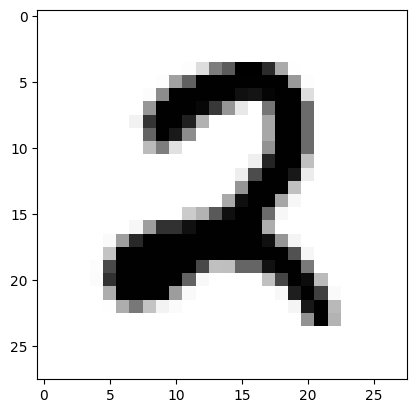

In [155]:
plt.imshow(random_image_tensor.squeeze().cpu(), cmap='gray_r')

In [157]:
from google.colab import files

uploaded = files.upload()

Saving 2_test_first_ai.png to 2_test_first_ai.png
